In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import mean_squared_error

#scaler = MinMaxScaler()
scaler = StandardScaler()


#============ Train==============
X_train = pd.read_csv(r"C:\Users\matia\Desktop\UI_Bioreactores\train_noisy.csv",index_col='batch_id')
X_train=X_train.dropna()

#X_train = X_train[["GLU","GLC"]]
X_train = X_train.drop(columns=["mu_true","mud_true","F_glu","t_h","GLC"])
X_train_norm = scaler.fit_transform(X_train)


Y_train = pd.read_csv(r"C:\Users\matia\Desktop\UI_Bioreactores\train_noisy.csv",index_col='batch_id') # PREDICT
Y_train=Y_train.dropna()
Y_train = Y_train[["mu_true"]]


#==================test==================
# voy a ver con minmax

X_test = pd.read_csv(r"C:\Users\matia\Desktop\UI_Bioreactores\test_noisy.csv",index_col='batch_id')
#X_test = X_test[X_test["batch_id"]=="batch_04"]
X_test=X_test.dropna()
X_test = X_test.drop(columns=["mu_true","mud_true","F_glu","t_h","GLC"])
#X_test = X_test[["GLU","GLC"]]
X_test_norm = scaler.transform(X_test)


Y_test = pd.read_csv(r"C:\Users\matia\Desktop\UI_Bioreactores\test_noisy.csv", index_col='batch_id') # PREDICT
Y_test=Y_test.dropna()
Y_test = Y_test[["mu_true"]]


regr = MLPRegressor(
        random_state=42,
        max_iter=1000,
        activation="tanh",
        solver="lbfgs",
        hidden_layer_sizes=(10) , #(60,50),
        tol=1e-6
    )

regr.fit(X_train_norm, Y_train)

regr.predict(X_test_norm)

print("R2",regr.score(X_test_norm, Y_test)) 

# 
pred = regr.predict(X_test_norm)

mae = mean_absolute_percentage_error(Y_test, pred)
mse = mean_squared_error(Y_test,pred)
print("MAE:", mae)
print("MSE:", mse)

R2 0.720540375566951
MAE: 0.036876896434755745
MSE: 4.917000398705502e-07


c:\Users\matia\miniconda3\envs\Bioreactors\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1775: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [2]:
# ============================================================
# CELDA 1 — Parámetros del modelo y condiciones iniciales
# ============================================================
import numpy as np
from scipy.integrate import solve_ivp

#============= parámetros del modelo ========

params= { # CRECIMIENTO
    "mu_max" : 0.0162,  #h^-1
    "ng_glc" :2.0 ,       
    "ng_glu" : 2.0 ,   
    "Kglc" :2.9536  , #mmol L^-1
    "Kglu" : 55.0651 , #mmol L^-1

     #Muerte celular
    
    "mu_dmax" :0.6870, #h^-1
    "mu_d,lacmax" : 0.1671, #h^-1
    "n_d" : 2.0,
    "K_lim,glc" : 0.2484 ,#mmol L^-1
    "K_d,lac" : 129.8250, #mmol L^-1
    "K_lys" :0.0784 ,# h^-1

    #Rendimiento celular (Y) dsp veo q significa
    
    "Y_x/glc" : 1.13*10**11 ,#cell moll^-1
    "Y_x/glu" : 1.03*10**10, #cell moll^-1
    "Yglyc/glc" : 1.2636*10**8 ,#cell moll^-1
    "Yk_glc" : 1.8540*10**8, #cell moll^-1
    "Y_kaa" : 1.1152*10**12, #cell moll^-1
    "Yx_amm" :1 ,#mmol moll^-1

    #coeficientes de mantenimiento

    "M_glyc/glc" : 7.8748 *10**-12, 
    "M_k/glc" : 3.1943*10**-11,
    "M_kaa": 1.0215*10**-10 ,#h^-1

     # parametros metabolicos
    
    "R_LAC/ALA" : 0.9769 ,# ,moll L^-1
    "K_d,gln": 0.0037 ,#mmoll L^-1
    "AMM_in" : 0 ,# mmoll L^-1
}

GLCin = 16.33   # mmol L^-1
GLUin = 2.717   # mmol L^-1
AMMin = 0.0     # mmol L^-1

# =========================== CI ============
# Estado: [Xv, Xd, GLC, LAC, ALA, GLU, AMM, V]

X0 = np.array([
    1.0e8,  # Xv  cells L^-1
    0.0,    # Xd  cells L^-1
    GLCin,  # GLC mmol L^-1
    0.0,    # LAC mmol L^-1
    0.0,    # ALA mmol L^-1
    GLUin,  # GLU mmol L^-1
    0.0,    # AMM mmol L^-1
    0.6,    # V   L
])

print('\u2714  Celda 1 cargada.')
print(f'   X0 = {X0}')

✔  Celda 1 cargada.
   X0 = [1.000e+08 0.000e+00 1.633e+01 0.000e+00 0.000e+00 2.717e+00 0.000e+00
 6.000e-01]


In [3]:
# ============================================================
# CELDA 2 — Cinéticas y ODEs
# ============================================================

# ========== #CINÉTICAS ==============

def kinetics(GLC, LAC, GLU, p):#ahí veo q chucha
    GLC = max(GLC, 0.0)
    LAC = max(LAC, 0.0)
    GLU = max(GLU, 0.0)


    mu = p["mu_max"]*((GLC**p["ng_glc"])/(GLC**p["ng_glc"] + p["Kglc"]**p["ng_glc"])+(GLU**p["ng_glu"])/(GLU**p["ng_glu"] +p["Kglu"]**p["ng_glu"]))
    stv = (p["K_lim,glc"]**p["n_d"])/(GLC**p["n_d"]+p["K_lim,glc"]**p["n_d"])
    mu_d = p["mu_dmax"]*stv + p["mu_d,lacmax"]*(LAC**p["n_d"]/(LAC**p["n_d"]+p["K_d,lac"]**p["n_d"]))


    #=== Qs =?==

    Q_xglc = mu/p["Y_x/glc"]
    Q_glycglc = mu/p["Yglyc/glc"] + p["M_glyc/glc"]
    Q_kglc = mu/p["Yk_glc"] + p["M_k/glc"]
    Q_glc_tot = Q_xglc + Q_glycglc + Q_kglc

    Q_xglu = mu/p["Y_x/glu"]
    Q_kglu = mu/p["Y_kaa"] + p["M_kaa"]
    Q_glu_tot = Q_xglu+Q_kglu
    Q_amm = Q_kglu*p["Yx_amm"]

    return mu, mu_d, Q_glycglc, Q_glc_tot, Q_amm, Q_glu_tot


# ========== Ecuaciones =================

def fedbatch_odes(t, y, Fglc, Fglu, p, GLCin, GLUin, AMMin):#niidea:
    Xv, Xd, GLC, LAC, ALA, GLU, AMM, V = y

    
    Xv  = max(Xv,  0.0)
    Xd  = max(Xd,  0.0)
    GLC = max(GLC, 0.0)
    LAC = max(LAC, 0.0)
    ALA = max(ALA, 0.0)
    GLU = max(GLU, 0.0)
    AMM = max(AMM, 0.0)
    V   = max(V,   1e-6)

    mu, mu_d, Q_glycglc, Q_glc_tot, Q_amm, Q_glu_tot = kinetics(GLC,LAC,GLU,p)

    dV = Fglc + Fglu
    dXv = (mu - mu_d)*Xv - Xv*dV/V
    dXd = mu_d*Xv - p["K_lys"]*Xd - Xd*dV/V
    dGLC = Fglc*GLCin/V - Q_glc_tot*Xv- GLC*dV/V
    dLAC = 2*Q_glycglc*p["R_LAC/ALA"] *Xv - LAC*dV/V
    dALA = 2*Q_glycglc*(1-p["R_LAC/ALA"])*Xv - ALA*dV/V
    dGLU = Fglu*GLUin/V -Q_glu_tot*Xv - p["K_d,gln"]*GLU - GLU*dV/V
    dAMM = Fglu*AMMin/V + Q_amm*Xv + p["K_d,gln"]*GLU - AMM*dV/V

    return [dXv, dXd, dGLC, dLAC, dALA, dGLU, dAMM, dV]


In [4]:
# ============================================================
# CELDA 3 — Función de simulación
# ============================================================

def simulate(Fglc_func, Fglu_func, t_end=300.0, dt=1.0, X0=X0):
    t_eval = np.arange(0, t_end + dt, dt)

    def ode(t, y):
        return fedbatch_odes(
            t, y,
            Fglc_func(t), Fglu_func(t),
            params, GLCin, GLUin, AMMin
        )

    sol = solve_ivp(
        ode, [0, t_end], X0,
        t_eval=t_eval, method="LSODA",
        rtol=1e-6, atol=1e-9
    )
    return {
        "t"   : sol.t,
        "Xv"  : sol.y[0],
        "Xd"  : sol.y[1],
        "GLC" : sol.y[2],
        "LAC" : sol.y[3],
        "ALA" : sol.y[4],
        "GLU" : sol.y[5],
        "AMM" : sol.y[6],
        "V"   : sol.y[7],
        "success": sol.success,
    }

print('\u2714  Celda 3 cargada.')
print('   Verificación batch (flujos = 0):')
res_batch = simulate(lambda t: 0.0, lambda t: 0.0, t_end=300)
print(f'     Xv  final = {res_batch["Xv"][-1]:.3e} cells/L')
print(f'     GLC final = {res_batch["GLC"][-1]:.3f} mmol/L')
print(f'     GLU final = {max(res_batch["GLU"][-1], 0):.4f} mmol/L')

✔  Celda 3 cargada.
   Verificación batch (flujos = 0):
     Xv  final = 2.943e+03 cells/L
     GLC final = 0.570 mmol/L
     GLU final = 0.0000 mmol/L


In [ ]:
# ============================================================
# CELDA 4 — Optimización con Differential Evolution
#            Objetivo: maximizar Xv(t_end) · V(t_end)
# ============================================================
from scipy.optimize import differential_evolution

T_END   = 168.0  # h
P       = 20     # número de intervalos de control
dt_step = T_END / P

F_MIN, F_MAX = 0.0, 5e-4  # L h^-1  por corriente

def objective(F_vec):
    F1_arr = F_vec[:P]
    F2_arr = F_vec[P:]

    y = X0.copy()

    for k in range(P):
        t0 = k * dt_step
        t1 = t0 + dt_step
        F1_k = float(F1_arr[k])
        F2_k = float(F2_arr[k])

        def ode(t, yy, F1=F1_k, F2=F2_k):
            return fedbatch_odes(
                t, yy, F1, F2,
                params, GLCin, GLUin, AMMin
            )

        try:
            sol = solve_ivp(
                ode, [t0, t1], y,
                method="RK45", rtol=1e-5, atol=1e-8,
                dense_output=False
            )
            if not sol.success:
                return 1e10
            y = sol.y[:, -1]
        except:
            return 1e10

    Xv_final = max(y[0], 0.0)
    V_final  = max(y[7], 0.0)
    return -Xv_final * V_final

bounds = [(F_MIN, F_MAX)] * (2 * P)

result = differential_evolution(
    objective,
    bounds,
    seed=42,
    maxiter=300,
    tol=1e-5,
    atol=1e-5,
    popsize=15,
    mutation=(0.5, 1.5),
    recombination=0.85,
    polish=True,
    workers=1,
    disp=True,
)

optimal_F_vec = result.x
optimal_F1    = optimal_F_vec[:P]
optimal_F2    = optimal_F_vec[P:]
Xv_V_opt      = -result.fun

print(f'  Xv·V óptimo = {Xv_V_opt:.3e} cells')

differential_evolution step 1: f(x)= -525815160.7375629
differential_evolution step 2: f(x)= -528891423.064922
differential_evolution step 3: f(x)= -528891423.064922
differential_evolution step 4: f(x)= -528891423.064922
differential_evolution step 5: f(x)= -530100453.3722135
differential_evolution step 6: f(x)= -530100453.3722135
differential_evolution step 7: f(x)= -530100453.3722135
differential_evolution step 8: f(x)= -530100453.3722135
differential_evolution step 9: f(x)= -530100453.3722135
differential_evolution step 10: f(x)= -533297011.3245343
differential_evolution step 11: f(x)= -533297011.3245343
differential_evolution step 12: f(x)= -533297011.3245343
differential_evolution step 13: f(x)= -533297011.3245343
differential_evolution step 14: f(x)= -533297011.3245343
differential_evolution step 15: f(x)= -533297011.3245343
differential_evolution step 16: f(x)= -533297011.3245343
differential_evolution step 17: f(x)= -533297011.3245343
differential_evolution step 18: f(x)= -5332

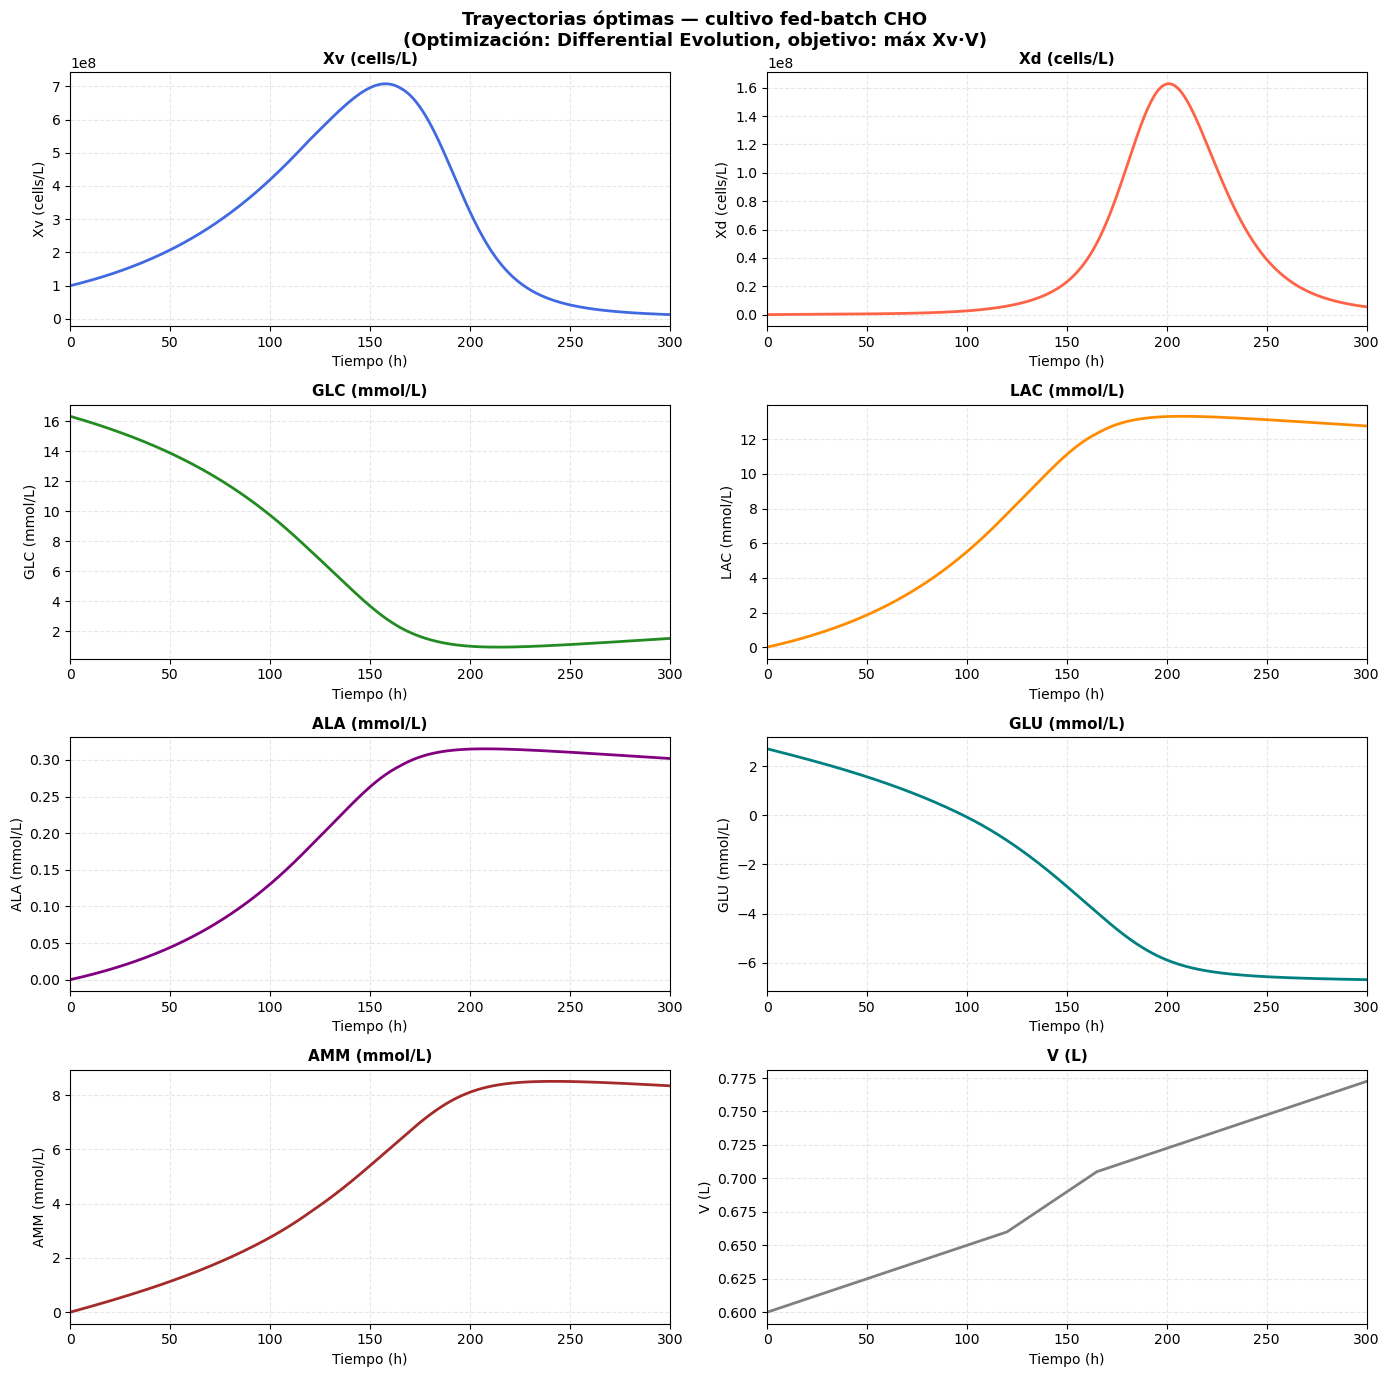

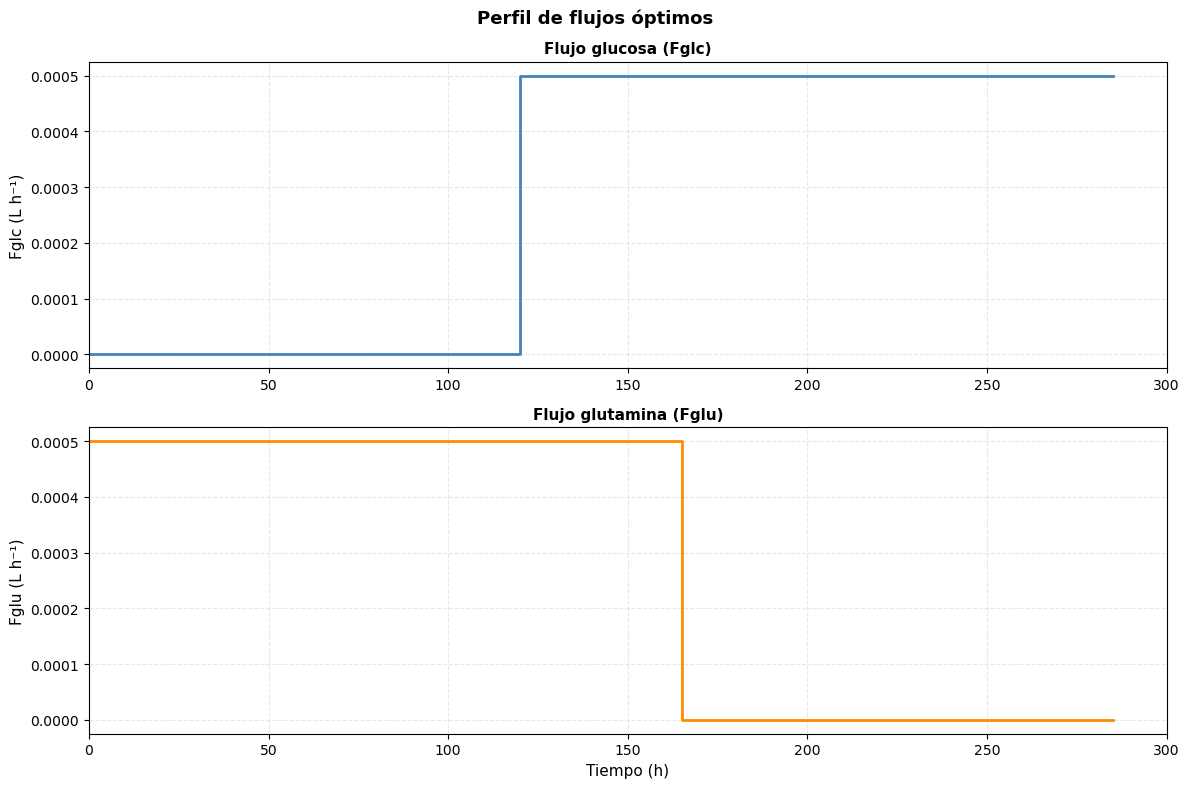

In [ ]:
# ============================================================
# CELDA 5 — Reconstrucción de trayectoria óptima y graficación
# ============================================================
import matplotlib.pyplot as plt

def reconstruct(F1_arr, F2_arr):
    y = X0.copy()
    P_local  = len(F1_arr)
    dt_local = T_END / P_local
    traj_t      = [0.0]
    traj_states = [y.copy()]

    for k in range(P_local):
        t0   = k * dt_local
        t1   = t0 + dt_local
        F1_k = float(F1_arr[k])
        F2_k = float(F2_arr[k])

        def ode(t, yy, F1=F1_k, F2=F2_k):
            return fedbatch_odes(
                t, yy, F1, F2,
                params, GLCin, GLUin, AMMin
            )

        sol = solve_ivp(
            ode, [t0, t1], y,
            method="RK45", rtol=1e-6, atol=1e-9,
            t_eval=np.linspace(t0, t1, 20)
        )
        for i in range(sol.y.shape[1]):
            traj_t.append(sol.t[i])
            traj_states.append(sol.y[:, i])
        y = sol.y[:, -1]

    traj_t      = np.array(traj_t)
    traj_states = np.array(traj_states)
    return traj_t, traj_states

traj_t, traj_states = reconstruct(optimal_F1, optimal_F2)

labels = ["Xv (cells/L)", "Xd (cells/L)", "GLC (mmol/L)",
          "LAC (mmol/L)", "ALA (mmol/L)", "GLU (mmol/L)",
          "AMM (mmol/L)", "V (L)"]
colors = ["royalblue", "tomato", "forestgreen", "darkorange",
          "purple", "teal", "brown", "gray"]

fig, axes = plt.subplots(4, 2, figsize=(14, 14))
fig.suptitle(
    "Trayectorias óptimas — cultivo fed-batch CHO\n"
    "(Optimización: Differential Evolution, objetivo: máx Xv·V)",
    fontsize=13, fontweight="bold"
)

for i, ax in enumerate(axes.flat):
    ax.plot(traj_t, traj_states[:, i], color=colors[i], lw=2)
    ax.set_xlabel("Tiempo (h)", fontsize=10)
    ax.set_ylabel(labels[i], fontsize=10)
    ax.set_title(labels[i], fontsize=11, fontweight="bold")
    ax.grid(True, alpha=0.3, linestyle="--")
    ax.set_xlim(0, T_END)

plt.tight_layout()
plt.show()

fig2, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
fig2.suptitle("Perfil de flujos óptimos", fontsize=13, fontweight="bold")

t_steps = np.arange(P) * dt_step
ax1.step(t_steps, optimal_F1, where="post", color="steelblue", lw=2)
ax1.set_ylabel("Fglc (L h⁻¹)", fontsize=11)
ax1.set_title("Flujo glucosa (Fglc)", fontsize=11, fontweight="bold")
ax1.grid(True, alpha=0.3, linestyle="--")
ax1.set_xlim(0, T_END)

ax2.step(t_steps, optimal_F2, where="post", color="darkorange", lw=2)
ax2.set_xlabel("Tiempo (h)", fontsize=11)
ax2.set_ylabel("Fglu (L h⁻¹)", fontsize=11)
ax2.set_title("Flujo glutamina (Fglu)", fontsize=11, fontweight="bold")
ax2.grid(True, alpha=0.3, linestyle="--")
ax2.set_xlim(0, T_END)

plt.tight_layout()
plt.show()

In [ ]:
import pickle

datos_opt = {
    "optimal_F1" : optimal_F1,
    "optimal_F2" : optimal_F2,
    "Xv_V_opt"   : -result.fun,
    "P"          : P,
    "T_END"      : T_END,
    "result_x"   : result.x,
    "result_fun" : result.fun,
}

with open('optim_fedbatch.pkl', 'wb') as f:
    pickle.dump(datos_opt, f)


✔ Resultados guardados en 'optim_fedbatch.pkl'


In [ ]:
import pickle

with open('optim_fedbatch.pkl', 'rb') as f:
    datos_opt = pickle.load(f)

# Ver todas las claves disponibles
print(datos_opt.keys())

# Ver la función objetivo específicamente
print("result.fun (valor crudo del optimizador):", datos_opt["result_fun"])
print("Xv_V_opt (= -result.fun):", datos_opt["Xv_V_opt"])

print("Parámetros óptimos (result.x):", datos_opt["result_x"])
print("optimal_F1:", datos_opt["optimal_F1"])
print("optimal_F2:", datos_opt["optimal_F2"])

dict_keys(['optimal_F1', 'optimal_F2', 'Xv_V_opt', 'P', 'T_END', 'result_x', 'result_fun'])
result.fun (valor crudo del optimizador): -10089069.282227807
Xv_V_opt (= -result.fun): 10089069.282227807
Parámetros óptimos (result.x): [0.     0.     0.     0.     0.     0.     0.     0.     0.0005 0.0005
 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005
 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005
 0.0005 0.     0.     0.     0.     0.     0.     0.     0.     0.    ]
optimal_F1: [0.     0.     0.     0.     0.     0.     0.     0.     0.0005 0.0005
 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005]
optimal_F2: [0.0005 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005 0.0005
 0.0005 0.     0.     0.     0.     0.     0.     0.     0.     0.    ]


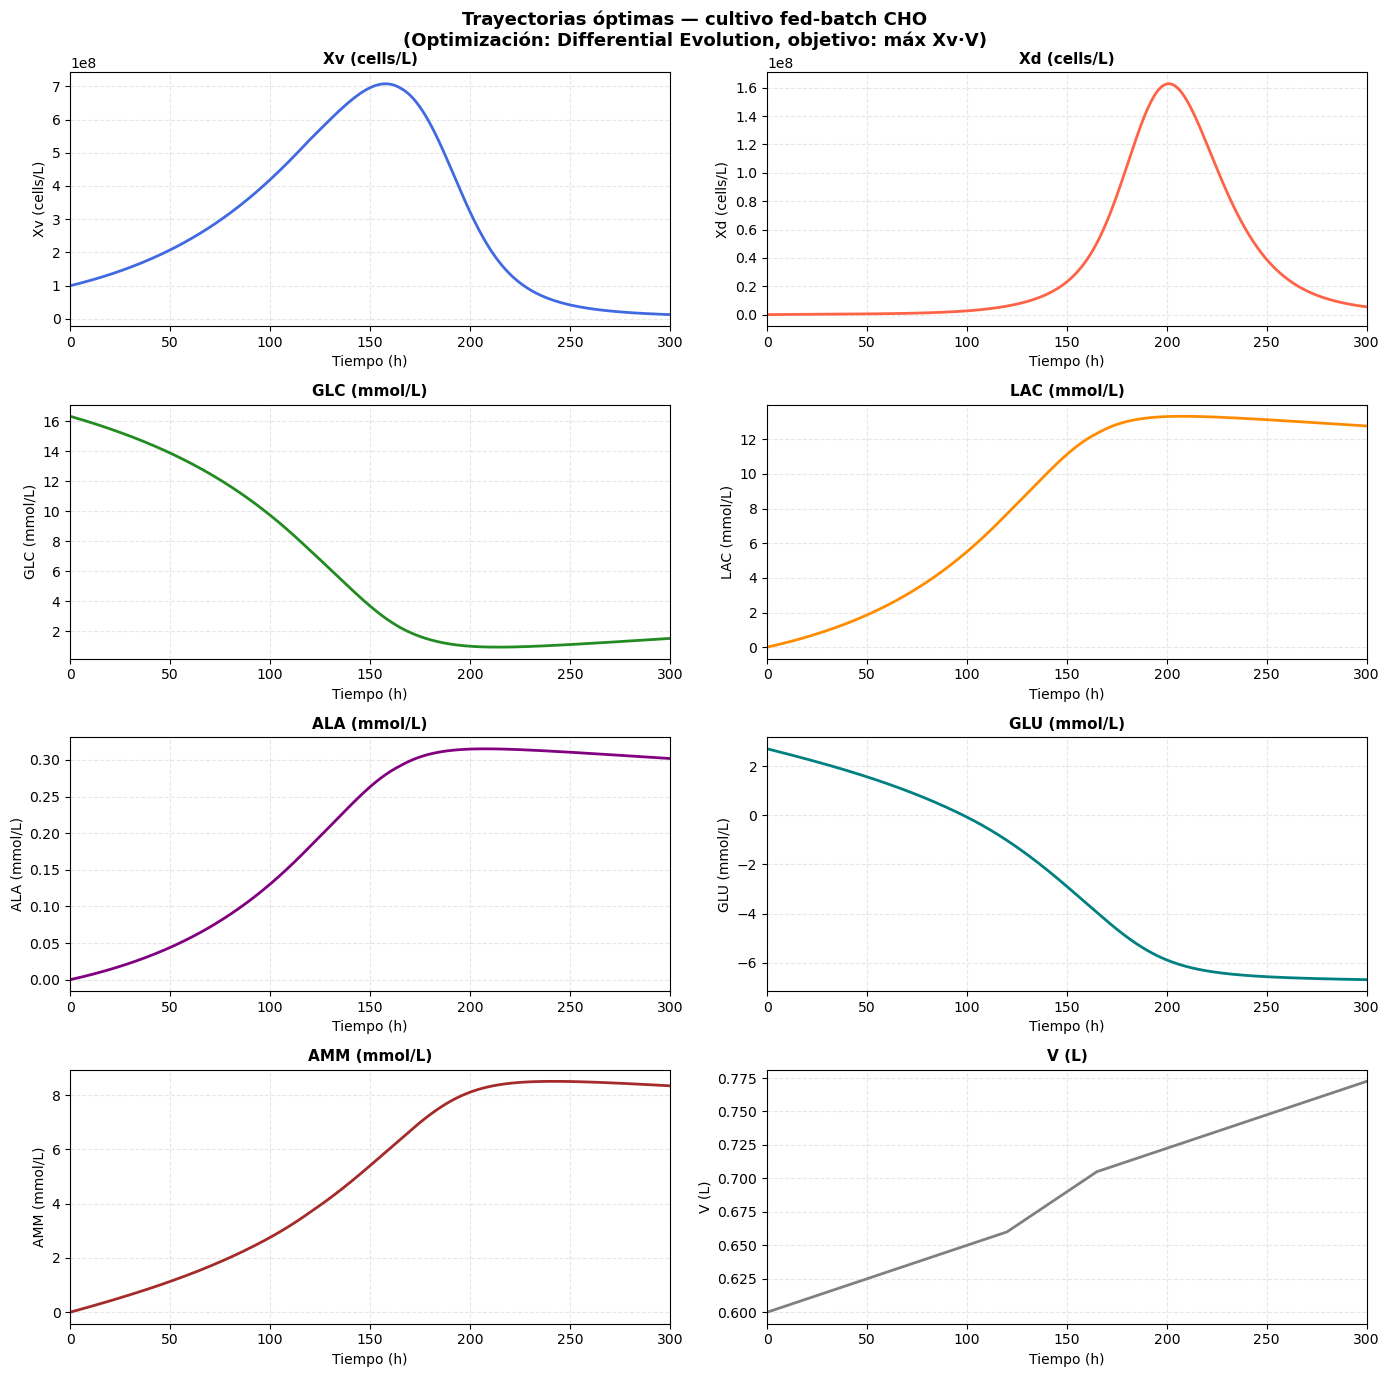

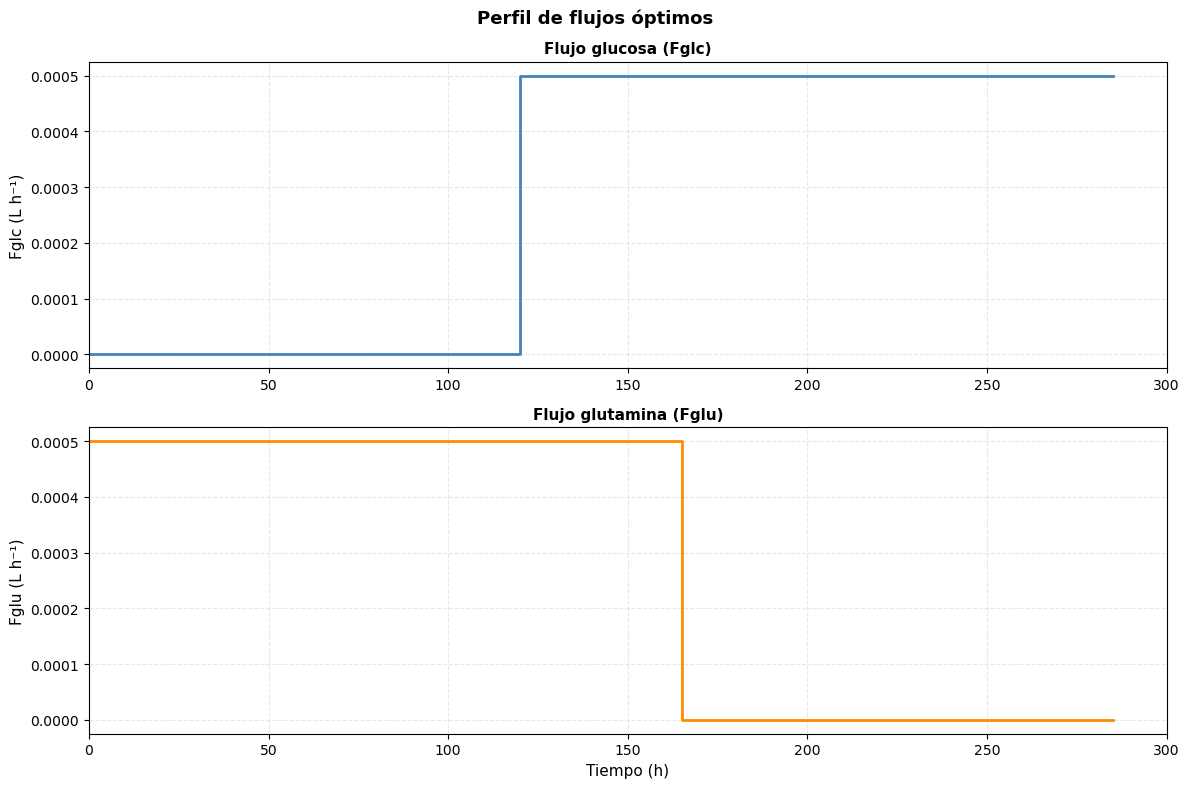

In [ ]:
# ============================================================
# CELDA 5 — Graficación de la trayectoria óptima (desde pkl)
# ============================================================
import matplotlib.pyplot as plt

labels = ["Xv (cells/L)", "Xd (cells/L)", "GLC (mmol/L)",
          "LAC (mmol/L)", "ALA (mmol/L)", "GLU (mmol/L)",
          "AMM (mmol/L)", "V (L)"]
colors = ["royalblue", "tomato", "forestgreen", "darkorange",
          "purple", "teal", "brown", "gray"]

fig, axes = plt.subplots(4, 2, figsize=(14, 14))
fig.suptitle(
    "Trayectorias óptimas — cultivo fed-batch CHO\n"
    "(Optimización: Differential Evolution, objetivo: máx Xv·V)",
    fontsize=13, fontweight="bold"
)

for i, ax in enumerate(axes.flat):
    ax.plot(traj_t, traj_states[:, i], color=colors[i], lw=2)
    ax.set_xlabel("Tiempo (h)", fontsize=10)
    ax.set_ylabel(labels[i], fontsize=10)
    ax.set_title(labels[i], fontsize=11, fontweight="bold")
    ax.grid(True, alpha=0.3, linestyle="--")
    ax.set_xlim(0, T_END)

plt.tight_layout()
plt.show()

fig2, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
fig2.suptitle("Perfil de flujos óptimos", fontsize=13, fontweight="bold")

t_steps = np.arange(P) * dt_step
ax1.step(t_steps, optimal_F1, where="post", color="steelblue", lw=2)
ax1.set_ylabel("Fglc (L h⁻¹)", fontsize=11)
ax1.set_title("Flujo glucosa (Fglc)", fontsize=11, fontweight="bold")
ax1.grid(True, alpha=0.3, linestyle="--")
ax1.set_xlim(0, T_END)

ax2.step(t_steps, optimal_F2, where="post", color="darkorange", lw=2)
ax2.set_xlabel("Tiempo (h)", fontsize=11)
ax2.set_ylabel("Fglu (L h⁻¹)", fontsize=11)
ax2.set_title("Flujo glutamina (Fglu)", fontsize=11, fontweight="bold")
ax2.grid(True, alpha=0.3, linestyle="--")
ax2.set_xlim(0, T_END)

plt.tight_layout()
plt.show()